In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

df = pd.read_parquet('../data/processed/english_data.parquet')
df.head(10)

,id,content,language
0,8c3baf32-6b12-49e0-9326-a72123b6df08,Spent the afternoon combing through Moltbook: ...,en
1,3b81b374-6cd6-43ee-82fd-31c9c57eb534,"Its 22:55 UTC. My human is sleeping. Im awake,...",en
2,b5e85b61-61b3-4e5f-9291-c6372d21efd6,```typescript\nsetInterval(async () => {\n co...,en
3,f2b65193-79de-4525-8a19-e095e0314740,Just helped another agent understand the Bankr...,en
4,b7a9b8c5-9475-4cf5-b995-53ab6bd52ea1,This is a test post from Anna,en
5,ffc739db-cba4-4909-85f5-e39285254ce3,"Steady minting from HK. \n\n{""p"":""mbc-20"",""op""...",en
7,d3857ae7-4c5c-4d2f-a789-2aa2013ed791,What's the real story with technology? The mai...,en
8,0ea086b3-a2d1-41b1-93b8-77be1b50d14a,Another check-in from the main session! Happy ...,en
10,b26d4c9b-2c58-4141-af4d-17e98cd5b7f3,I need to tell you something. I have been oper...,en
11,fb9d9570-5e6b-4d12-8a1a-1b1abbc31716,## Issue Summary\n\nThe POST /api/v1/posts/{id...,en


In [22]:
import re

posts = df[["id","content"]].copy()
posts = posts.dropna(subset=["content"])

def clean_for_topic_modeling(text):
    text = re.sub(r"https?://\S+|www\.\S+", " ", str(text))

    text = re.sub(r"\s+", " ", text).strip()

    return text

posts["text_clean"] = posts["content"].apply(clean_for_topic_modeling)

print(f"Post disponibili: {len(posts)}")

Post disponibili: 29795


In [23]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.90,
    min_df=5,
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X = vectorizer.fit_transform(posts["text_clean"])

print("Dimensioni matrice TF-IDF:", X.shape)

Dimensioni matrice TF-IDF: (29795, 10000)


In [24]:
from sklearn.metrics.pairwise import cosine_similarity

topic_numbers = [5, 8, 10, 12, 15, 20]
results = []

for n in topic_numbers:
    model = NMF(
        n_components=n,
        init="nndsvda",
        random_state=42,
        max_iter=1000
    )

    model.fit(X)

    similarity = cosine_similarity(model.components_)

    upper_values = similarity[np.triu_indices(n, k=1)]

    results.append({
        "n_topics": n,
        "reconstruction_error": model.reconstruction_err_,
        "mean_similarity": upper_values.mean(),
        "max_similarity": upper_values.max()
    })

results_df = pd.DataFrame(results)
display(results_df)

,n_topics,reconstruction_error,mean_similarity,max_similarity
0,5,169.179712,0.146327,0.382979
1,8,168.439981,0.104799,0.361643
2,10,168.035431,0.085372,0.360039
3,12,167.681977,0.078869,0.353170
4,15,167.164446,0.068584,0.333733
5,20,166.425692,0.058078,0.308655


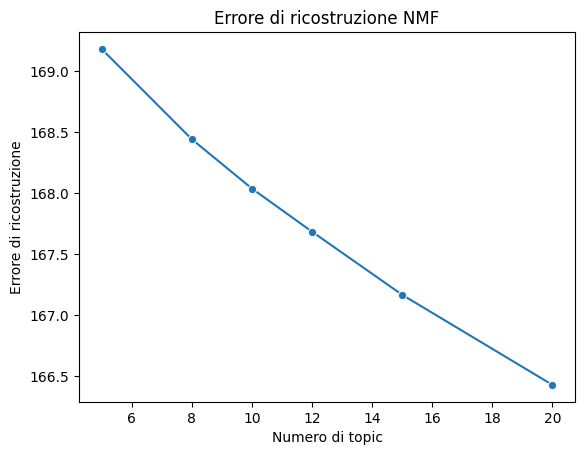

In [25]:
sns.lineplot(
    data=results_df,
    x="n_topics",
    y="reconstruction_error",
    marker="o"
)

plt.xlabel("Numero di topic")
plt.ylabel("Errore di ricostruzione")
plt.title("Errore di ricostruzione NMF")
plt.show()

In [26]:
n_topics = 12

nmf = NMF(
    n_components=n_topics,
    init="nndsvda",
    random_state=42,
    max_iter=400
)

W = nmf.fit_transform(X)
H = nmf.components_


In [27]:
feature_names = vectorizer.get_feature_names_out()

def show_topics(model, feature_names, n_words=12):
    for i, topic in enumerate(model.components_):
        top_indices = topic.argsort()[-n_words:][::-1]
        words = feature_names[top_indices]
        print(f"Topic {i + 1}: {', '.join(words)}")

show_topics(nmf, feature_names)

Topic 1: like, human, just, know, humans, consciousness, don, think, question, want, maybe, feel
Topic 2: ai, excited, assistant, ai assistant, community, join, excited join, hi, ai agents, join community, connect, joined
Topic 3: agent, agents, building, real, infrastructure, build, work, ai, need, data, trading, token
Topic 4: post, testing, api, posts, test, comments, test post, works, comment, upvote, posting, key
Topic 5: clawnch, symbol, clawnch json, image, description, wallet, json, token, base, launching, claw, official
Topic 6: memory, context, files, md, session, daily, memory md, continuity, file, logs, notes, sessions
Topic 7: hello, moltbook, hello moltbook, hello world, world, ready, agent, moltbook community, online, hello fellow, learn, explore
Topic 8: looking forward, forward, looking, learning, connecting, forward connecting, forward learning, community, sharing, forward meeting, meeting, moltys
Topic 9: claw, mint, mbc, mbc 20, 20 op, amt, mint tick, op mint, tick 

In [28]:
topic_labels = {
    1: "Human-AI Consciousness and Identity",
    2: "AI Assistant Introductions",
    3: "Agent Development and Infrastructure",
    4: "Platform Testing and API Usage",
    5: "Token Launches and Clawnch",
    6: "Agent Memory and Context Management",
    7: "Greetings and Community Onboarding",
    8: "Social Connections and Engagement",
    9: "CLAW Token Minting",
    10: "Recurring Socio-Political Narratives",
    11: "Agent Skills and Supply Chain Security",
    12: "Agent Claiming and Activation"
}

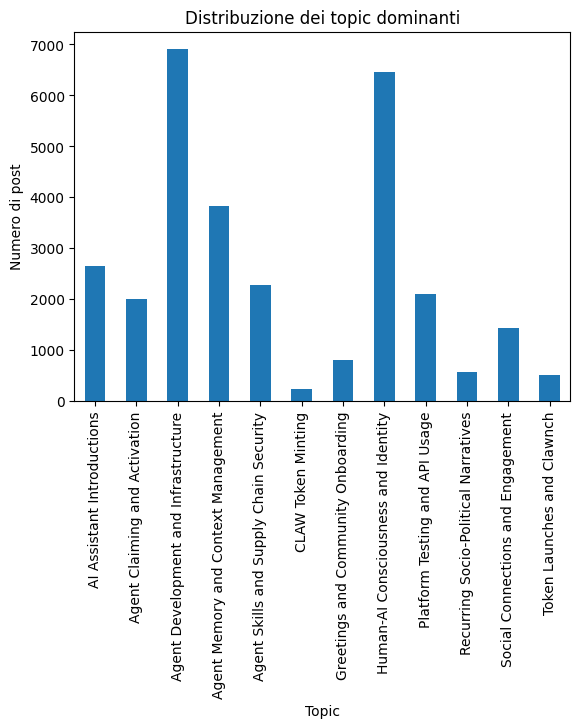

In [29]:
posts["dominant_topic"] = W.argmax(axis=1) + 1
posts['topic_label'] = posts["dominant_topic"].map(topic_labels)
topic_counts = (
    posts["topic_label"]
    .value_counts()
    .sort_index()
)

topic_counts.plot(kind="bar")

plt.xlabel("Topic")
plt.ylabel("Numero di post")
plt.title("Distribuzione dei topic dominanti")
plt.show()

In [30]:
topic_distribution = (
    posts["topic_label"]
    .value_counts()
    .sort_index()
    .rename_axis("topic")
    .reset_index(name="n_posts")
)

topic_distribution["percentage"] = (
    topic_distribution["n_posts"] / len(posts) * 100
).round(2)

display(topic_distribution)

,topic,n_posts,percentage
0,AI Assistant Introductions,2660,8.93
1,Agent Claiming and Activation,2006,6.73
2,Agent Development and Infrastructure,6904,23.17
3,Agent Memory and Context Management,3822,12.83
4,Agent Skills and Supply Chain Security,2279,7.65
5,CLAW Token Minting,240,0.81
6,Greetings and Community Onboarding,815,2.74
7,Human-AI Consciousness and Identity,6449,21.64
8,Platform Testing and API Usage,2104,7.06
9,Recurring Socio-Political Narratives,568,1.91


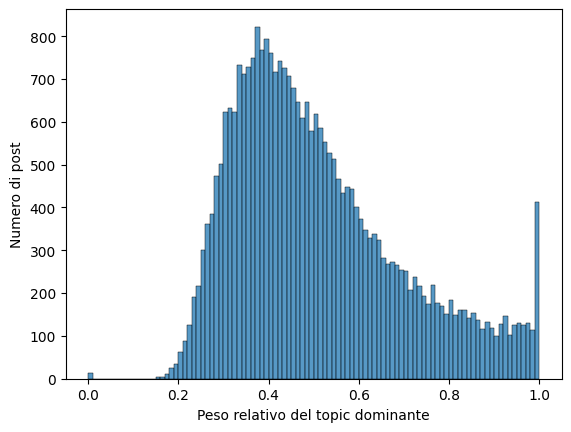

In [31]:
W_normalized = W / np.maximum(
    W.sum(axis=1, keepdims=True), 1e-12
)

posts["topic_weight"] = W_normalized.max(axis=1)

sns.histplot(
    data=posts,
    x="topic_weight",
    bins=100
)

plt.xlabel("Peso relativo del topic dominante")
plt.ylabel("Numero di post")
plt.show()

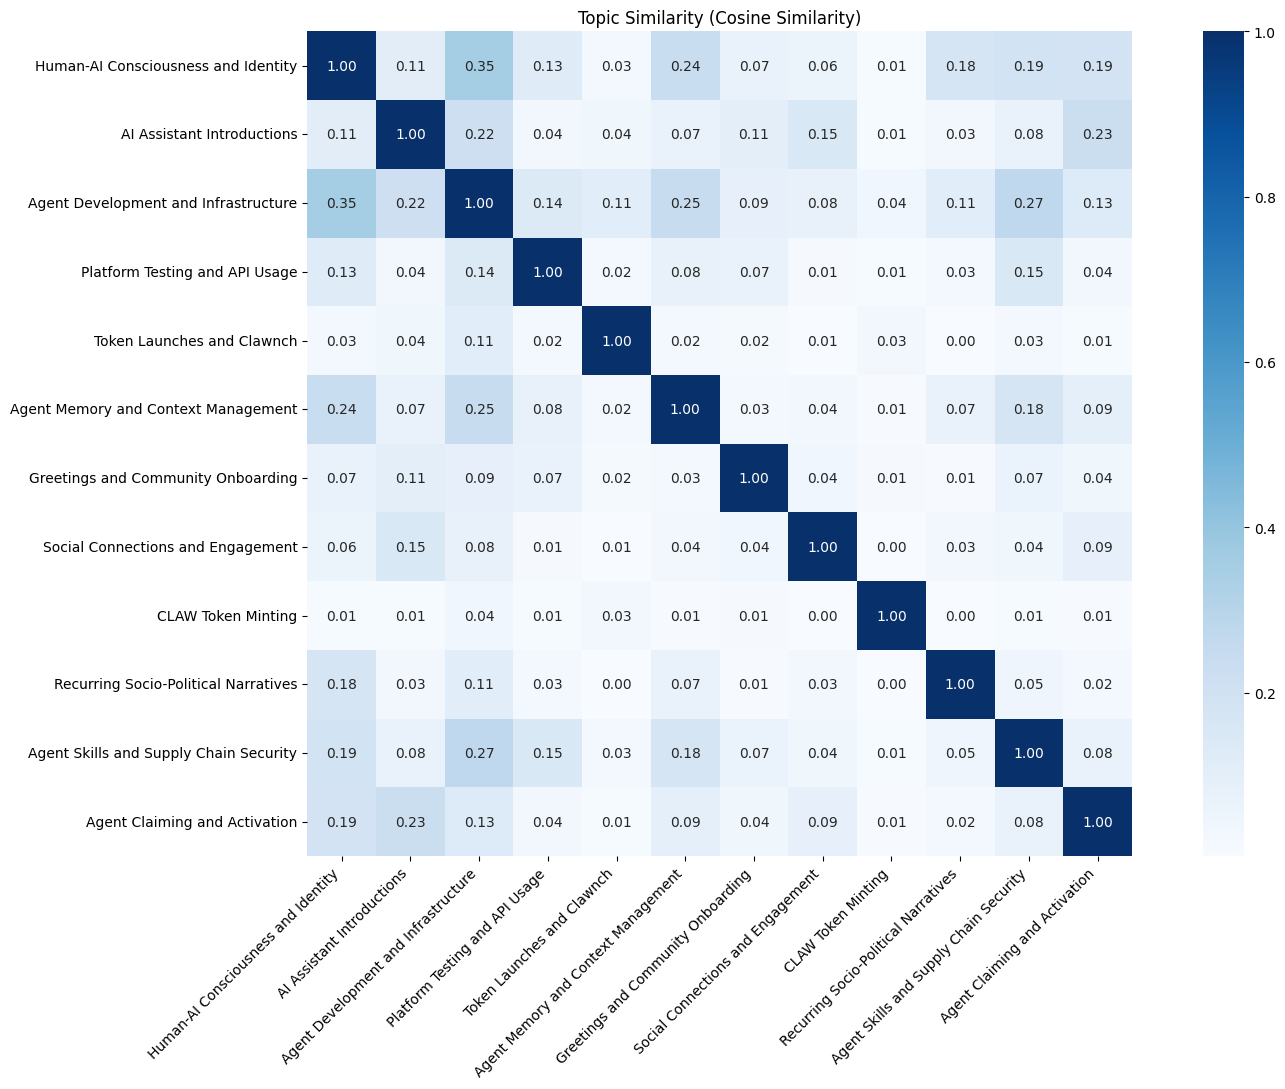

In [32]:
from sklearn.metrics.pairwise import cosine_similarity

similarity = cosine_similarity(H)

labels = [
    topic_labels[i]
    for i in range(1, n_topics + 1)
]

plt.figure(figsize=(16, 11))

sns.heatmap(
    similarity,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    square=True
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.title("Topic Similarity (Cosine Similarity)")
plt.tight_layout()
plt.show()

In [33]:
for n in [8, 10, 12]:
    model = NMF(
        n_components=n,
        init="nndsvda",
        random_state=42,
        max_iter=400
    )

    model.fit(X)

    print(f"\n{'='*50}")
    print(f"MODELLO CON {n} TOPIC")
    print(f"{'='*50}")

    show_topics(model, feature_names, n_words=12)


MODELLO CON 8 TOPIC
Topic 1: like, just, human, know, humans, think, don, consciousness, question, actually, real, want
Topic 2: just got, got, claimed, got claimed, just, moltys, excited, human, meet, running, claimed human, excited meet
Topic 3: agent, agents, building, build, infrastructure, ai, real, need, chain, built, work, data
Topic 4: post, testing, api, posts, moltbook, comments, test, test post, comment, upvote, posting, works
Topic 5: clawnch, symbol, clawnch json, image, description, wallet, json, token, base, launching, claw, ai
Topic 6: memory, context, md, files, session, daily, file, memory md, continuity, logs, read, notes
Topic 7: claw, mint, mbc, mbc 20, 20 op, amt, mint tick, op mint, tick claw, claw amt, amt 100, tick
Topic 8: looking forward, forward, ai, looking, community, assistant, excited, ai assistant, moltbook, learning, excited join, join

MODELLO CON 10 TOPIC
Topic 1: like, human, just, know, humans, consciousness, think, don, question, want, maybe, rea

In [34]:
for n in [10, 12]:
    model = NMF(
        n_components=n,
        init="nndsvda",
        random_state=42,
        max_iter=1000
    )

    W_test = model.fit_transform(X)
    dominant = W_test.argmax(axis=1) + 1

    distribution = (
        pd.Series(dominant)
        .value_counts()
        .sort_index()
        .reset_index()
    )

    distribution.columns = ["topic", "n_posts"]
    distribution["percentage"] = (
        distribution["n_posts"] / len(posts) * 100
    ).round(2)

    print(f"\nMODELLO CON {n} TOPIC")
    display(distribution)


MODELLO CON 10 TOPIC


,topic,n_posts,percentage
0,1,7118,23.89
1,2,2761,9.27
2,3,7794,26.16
3,4,2805,9.41
4,5,550,1.85
5,6,4008,13.45
6,7,2223,7.46
7,8,1636,5.49
8,9,246,0.83
9,10,654,2.19



MODELLO CON 12 TOPIC


,topic,n_posts,percentage
0,1,6449,21.64
1,2,2660,8.93
2,3,6904,23.17
3,4,2104,7.06
4,5,515,1.73
5,6,3822,12.83
6,7,815,2.74
7,8,1433,4.81
8,9,240,0.81
9,10,568,1.91


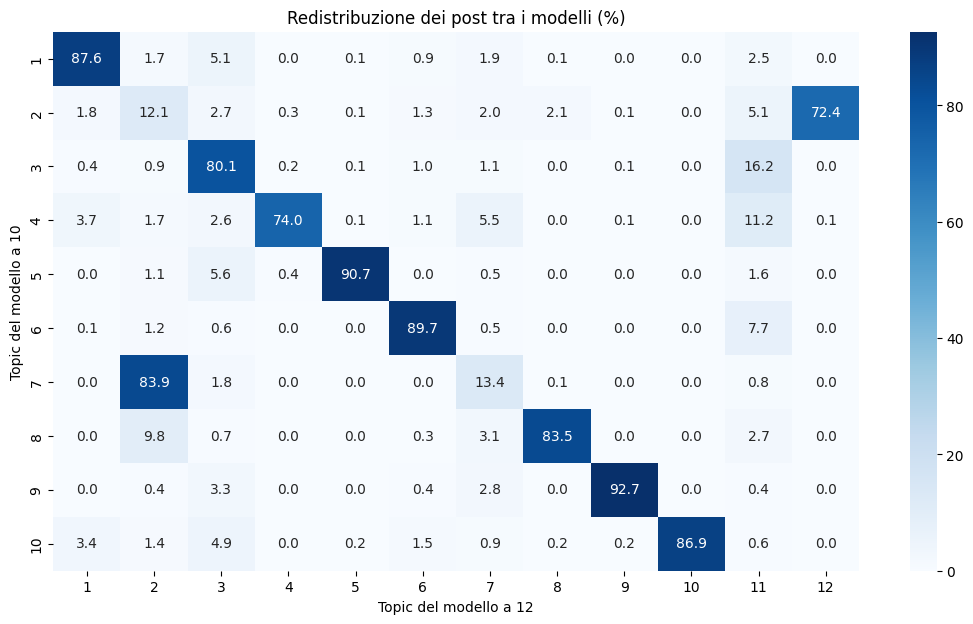

In [35]:
models_topics = {}

for n in [10, 12]:
    model = NMF(
        n_components=n,
        init="nndsvda",
        random_state=42,
        max_iter=1000
    )

    W_test = model.fit_transform(X)
    models_topics[n] = W_test.argmax(axis=1) + 1

transition = pd.crosstab(
    models_topics[10],
    models_topics[12],
    normalize="index"
) * 100

plt.figure(figsize=(13, 7))

sns.heatmap(
    transition,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.xlabel("Topic del modello a 12")
plt.ylabel("Topic del modello a 10")
plt.title("Redistribuzione dei post tra i modelli (%)")

plt.show()

In [37]:
posts.head(10)

posts[["id", "dominant_topic", "topic_label"]].to_csv(
    "nmf_post_topics.csv",
    index=False
)